## Lab 2
### Part 2: Dealing with overfitting

Today we work with [Fashion-MNIST dataset](https://github.com/zalandoresearch/fashion-mnist) (*hint: it is available in `torchvision`*).

Your goal for today:
1. Train a FC (fully-connected) network that achieves >= 0.885 test accuracy.
2. Cause considerable overfitting by modifying the network (e.g. increasing the number of network parameters and/or layers) and demonstrate in in the appropriate way (e.g. plot loss and accurasy on train and validation set w.r.t. network complexity).
3. Try to deal with overfitting (at least partially) by using regularization techniques (Dropout/Batchnorm/...) and demonstrate the results.

__Please, write a small report describing your ideas, tries and achieved results in the end of this file.__

*Note*: Tasks 2 and 3 are interrelated, in task 3 your goal is to make the network from task 2 less prone to overfitting. Task 1 is independent from 2 and 3.

*Note 2*: We recomment to use Google Colab or other machine with GPU acceleration.

In [11]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import torchsummary
from IPython.display import clear_output
from matplotlib import pyplot as plt
from matplotlib.pyplot import figure
import numpy as np
import os


device = 'cuda:0' if torch.cuda.is_available() else 'cpu'

In [12]:
# Technical function
def mkdir(path):
    if not os.path.exists(root_path):
        os.mkdir(root_path)
        print('Directory', path, 'is created!')
    else:
        print('Directory', path, 'already exists!')
        
root_path = 'fmnist'
mkdir(root_path)

Directory fmnist already exists!


In [13]:
download = True
train_transform = transforms.ToTensor()
test_transform = transforms.ToTensor()
transforms.Compose((transforms.ToTensor()))


fmnist_dataset_train = torchvision.datasets.FashionMNIST(root_path, 
                                                        train=True, 
                                                        transform=train_transform,
                                                        target_transform=None,
                                                        download=download)
fmnist_dataset_test = torchvision.datasets.FashionMNIST(root_path, 
                                                       train=False, 
                                                       transform=test_transform,
                                                       target_transform=None,
                                                       download=download)

In [14]:
train_loader = torch.utils.data.DataLoader(fmnist_dataset_train, 
                                           batch_size=128,
                                           shuffle=True,
                                           num_workers=2)
test_loader = torch.utils.data.DataLoader(fmnist_dataset_test,
                                          batch_size=256,
                                          shuffle=False,
                                          num_workers=2)

In [15]:
len(fmnist_dataset_test)

10000

In [16]:
for img, label in train_loader:
    print(img.shape)
#     print(img)
    print(label.shape)
    print(label.size(0))
    break

torch.Size([128, 1, 28, 28])
torch.Size([128])
128


In [17]:
import torch.nn.functional as F
from time import time

torch.manual_seed(0)
np.random.seed(0)

X_train_full = fmnist_dataset_train.data.float().div(255).unsqueeze(1)
y_train_full = fmnist_dataset_train.targets
X_test = fmnist_dataset_test.data.float().div(255).unsqueeze(1)
y_test = fmnist_dataset_test.targets
print(X_train_full.shape, X_test.shape)


def evaluate(model, X, y, batch_size=2048):
    model.eval()
    total_loss, correct = 0., 0
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            xb, yb = X[i:i + batch_size].to(device), y[i:i + batch_size].to(device)
            logits = model(xb)
            total_loss += F.cross_entropy(logits, yb, reduction='sum').item()
            correct += (logits.argmax(dim=1) == yb).sum().item()
    return total_loss / len(X), correct / len(X)


def fit(model, opt, loss_func, X, y, n_epochs, batch_size=128, scheduler=None, verbose=True):
    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
    for epoch in range(n_epochs):
        start = time()
        model.train()
        permutation = torch.randperm(len(X))
        for i in range(0, len(X), batch_size):
            idx = permutation[i:i + batch_size]
            xb, yb = X[idx].to(device), y[idx].to(device)
            opt.zero_grad()
            loss = loss_func(model(xb), yb)
            loss.backward()
            opt.step()
        if scheduler is not None:
            scheduler.step()
        for split, (X_eval, y_eval) in (('train', (X, y)), ('test', (X_test, y_test))):
            split_loss, split_acc = evaluate(model, X_eval, y_eval)
            history[split + '_loss'].append(split_loss)
            history[split + '_acc'].append(split_acc)
        if verbose:
            print('epoch %3d | train loss %.4f acc %.4f | test loss %.4f acc %.4f | %.1f s'
                  % (epoch + 1, history['train_loss'][-1], history['train_acc'][-1],
                     history['test_loss'][-1], history['test_acc'][-1], time() - start))
    return history


SERIES_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#3d3d3a',
    'xtick.color': '#5f5e5a', 'ytick.color': '#5f5e5a',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
    'lines.linewidth': 2, 'legend.frameon': False, 'font.size': 11,
})


def plot_histories(histories, title):
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(14, 5))
    for color, (name, h) in zip(SERIES_COLORS, histories.items()):
        epochs = np.arange(1, len(h['train_loss']) + 1)
        ax_loss.plot(epochs, h['train_loss'], '-', color=color, label=name + ', train')
        ax_loss.plot(epochs, h['test_loss'], '--', color=color, label=name + ', test')
        ax_acc.plot(epochs, h['train_acc'], '-', color=color, label=name + ', train')
        ax_acc.plot(epochs, h['test_acc'], '--', color=color, label=name + ', test')
    ax_loss.set_yscale('log')
    ax_loss.set_xlabel('Epoch')
    ax_loss.set_ylabel('Cross-entropy loss, log scale')
    ax_loss.set_title('Loss', loc='left')
    ax_acc.set_xlabel('Epoch')
    ax_acc.set_ylabel('Accuracy')
    ax_acc.set_title('Accuracy', loc='left')
    ax_acc.legend(title='solid: train, dashed: test', fontsize=9)
    fig.suptitle(title, x=0.01, ha='left')
    plt.tight_layout()
    plt.show()

torch.Size([60000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


### Task 1
Train a network that achieves $\geq 0.885$ test accuracy. It's fine to use only Linear (`nn.Linear`) layers and activations/dropout/batchnorm. Convolutional layers might be a great use, but we will meet them a bit later.

In [18]:
class TinyNeuralNetwork(nn.Module):
    def __init__(self, input_shape=28*28, num_classes=10, input_channels=1):
        super(self.__class__, self).__init__()
        self.model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_shape, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )

    def forward(self, inp):
        out = self.model(inp)
        return out

In [19]:
torchsummary.summary(TinyNeuralNetwork().to(device), (28*28,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
           Flatten-1                  [-1, 784]               0
            Linear-2                  [-1, 512]         401,920
       BatchNorm1d-3                  [-1, 512]           1,024
              ReLU-4                  [-1, 512]               0
           Dropout-5                  [-1, 512]               0
            Linear-6                  [-1, 256]         131,328
       BatchNorm1d-7                  [-1, 256]             512
              ReLU-8                  [-1, 256]               0
           Dropout-9                  [-1, 256]               0
           Linear-10                   [-1, 10]           2,570
Total params: 537,354
Trainable params: 537,354
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.03
Params size (MB): 2.05
Estimated T

Your experiments come here:

epoch   1 | train loss 0.3678 acc 0.8618 | test loss 0.4167 acc 0.8473 | 2.9 s
epoch   2 | train loss 0.3221 acc 0.8801 | test loss 0.3828 acc 0.8564 | 3.1 s
epoch   3 | train loss 0.2742 acc 0.8962 | test loss 0.3479 acc 0.8698 | 2.5 s
epoch   4 | train loss 0.2741 acc 0.8960 | test loss 0.3462 acc 0.8698 | 3.1 s
epoch   5 | train loss 0.2411 acc 0.9111 | test loss 0.3292 acc 0.8812 | 3.1 s
epoch   6 | train loss 0.2034 acc 0.9248 | test loss 0.3108 acc 0.8893 | 3.2 s
epoch   7 | train loss 0.1852 acc 0.9315 | test loss 0.3010 acc 0.8937 | 3.4 s
epoch   8 | train loss 0.1944 acc 0.9265 | test loss 0.3193 acc 0.8872 | 3.1 s
epoch   9 | train loss 0.1639 acc 0.9411 | test loss 0.2931 acc 0.8961 | 3.1 s
epoch  10 | train loss 0.1558 acc 0.9433 | test loss 0.2942 acc 0.8971 | 3.0 s
epoch  11 | train loss 0.1355 acc 0.9508 | test loss 0.2872 acc 0.9016 | 2.9 s
epoch  12 | train loss 0.1381 acc 0.9500 | test loss 0.2985 acc 0.8953 | 2.9 s
epoch  13 | train loss 0.1229 acc 0.9559 | test loss

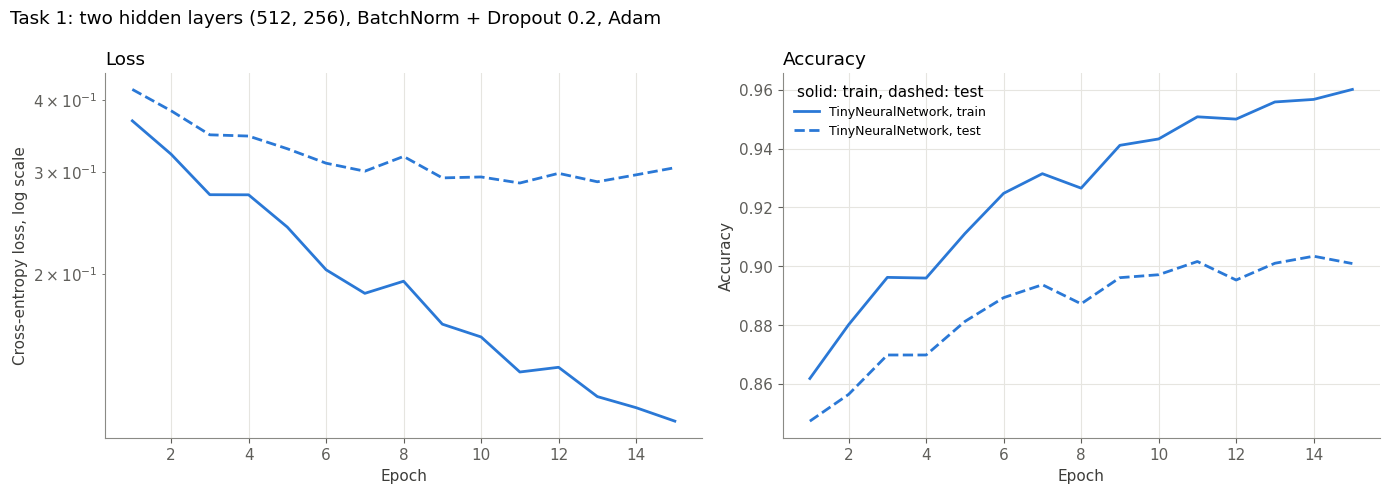

Final test accuracy: 0.9009


In [20]:
torch.manual_seed(0)
model = TinyNeuralNetwork().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_func = nn.CrossEntropyLoss()
scheduler = torch.optim.lr_scheduler.StepLR(opt, step_size=5, gamma=0.5)

tiny_history = fit(model, opt, loss_func, X_train_full, y_train_full, n_epochs=15, scheduler=scheduler)
plot_histories({'TinyNeuralNetwork': tiny_history}, 'Task 1: two hidden layers (512, 256), BatchNorm + Dropout 0.2, Adam')
print('Final test accuracy: %.4f' % tiny_history['test_acc'][-1])

### Task 2: Overfit it.
Build a network that will overfit to this dataset. Demonstrate the overfitting in the appropriate way (e.g. plot loss and accurasy on train and test set w.r.t. network complexity).

*Note:* you also might decrease the size of `train` dataset to enforce the overfitting and speed up the computations.

In [21]:
class OverfittingNeuralNetwork(nn.Module):
    def __init__(self, input_shape=28*28, num_classes=10, input_channels=1, hidden_size=1024, n_hidden_layers=3):
        super(self.__class__, self).__init__()
        layers = [nn.Flatten()]
        n_in = input_shape
        for _ in range(n_hidden_layers):
            layers += [nn.Linear(n_in, hidden_size), nn.ReLU()]
            n_in = hidden_size
        layers.append(nn.Linear(n_in, num_classes))
        self.model = nn.Sequential(*layers)

    def forward(self, inp):
        out = self.model(inp)
        return out

In [22]:
torchsummary.summary(OverfittingNeuralNetwork().to(device), (28*28,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
           Flatten-1                  [-1, 784]               0
            Linear-2                 [-1, 1024]         803,840
              ReLU-3                 [-1, 1024]               0
            Linear-4                 [-1, 1024]       1,049,600
              ReLU-5                 [-1, 1024]               0
            Linear-6                 [-1, 1024]       1,049,600
              ReLU-7                 [-1, 1024]               0
            Linear-8                   [-1, 10]          10,250
Total params: 2,913,290
Trainable params: 2,913,290
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.05
Params size (MB): 11.11
Estimated Total Size (MB): 11.17
----------------------------------------------------------------


Small train set: torch.Size([3000, 1, 28, 28])  class counts: [319, 288, 287, 277, 291, 299, 299, 324, 304, 312]


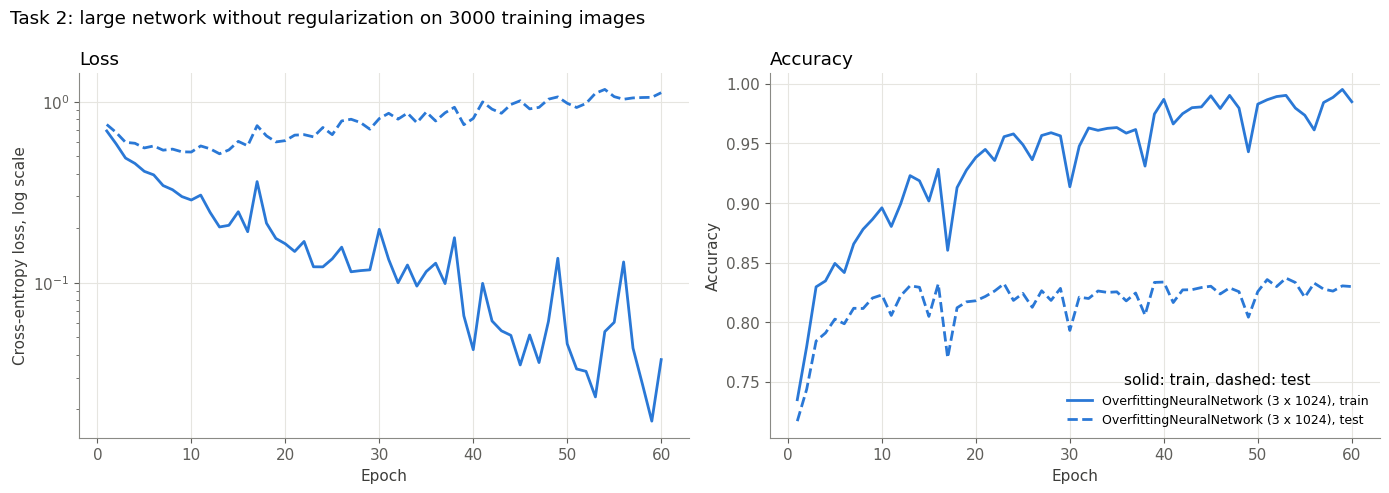

Test loss is minimal at epoch 13 (0.5152), at the end it is 1.1195
Final accuracy: train 0.9850, test 0.8299


In [23]:
N_SMALL, N_EPOCHS_SMALL = 3000, 60
subset_idx = torch.randperm(len(X_train_full), generator=torch.Generator().manual_seed(0))[:N_SMALL]
X_small, y_small = X_train_full[subset_idx], y_train_full[subset_idx]
print('Small train set:', X_small.shape, ' class counts:', torch.bincount(y_small).tolist())

torch.manual_seed(0)
model = OverfittingNeuralNetwork().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_func = nn.CrossEntropyLoss()

overfit_history = fit(model, opt, loss_func, X_small, y_small, n_epochs=N_EPOCHS_SMALL, verbose=False)
plot_histories({'OverfittingNeuralNetwork (3 x 1024)': overfit_history},
               'Task 2: large network without regularization on 3000 training images')

best_epoch = int(np.argmin(overfit_history['test_loss']))
print('Test loss is minimal at epoch %d (%.4f), at the end it is %.4f'
      % (best_epoch + 1, overfit_history['test_loss'][best_epoch], overfit_history['test_loss'][-1]))
print('Final accuracy: train %.4f, test %.4f'
      % (overfit_history['train_acc'][-1], overfit_history['test_acc'][-1]))

hidden   16 | params     13274 | train loss 0.3055 acc 0.8963 | test loss 0.5495 acc 0.8161
hidden   64 | params     59210 | train loss 0.1691 acc 0.9433 | test loss 0.6997 acc 0.8116
hidden  256 | params    335114 | train loss 0.0249 acc 0.9937 | test loss 0.9345 acc 0.8212
hidden 1024 | params   2913290 | train loss 0.0377 acc 0.9850 | test loss 1.1195 acc 0.8299


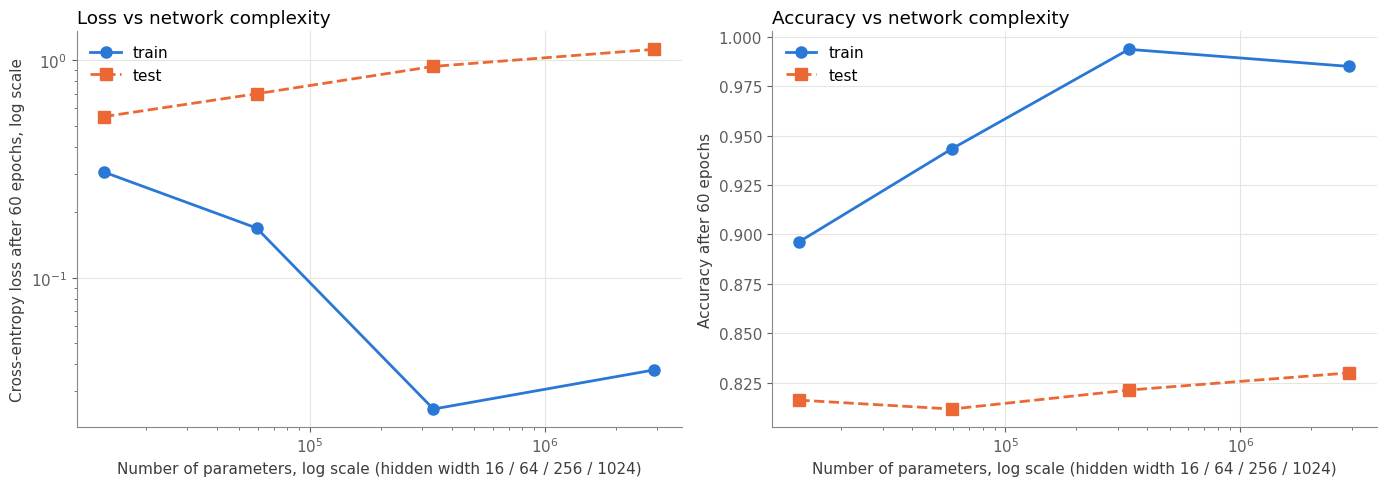

In [24]:
hidden_sizes = [16, 64, 256, 1024]
complexity = {}
for hidden_size in hidden_sizes:
    if hidden_size == 1024:
        history, n_params = overfit_history, sum(p.numel() for p in model.parameters())
    else:
        torch.manual_seed(0)
        net = OverfittingNeuralNetwork(hidden_size=hidden_size).to(device)
        history = fit(net, torch.optim.Adam(net.parameters(), lr=1e-3), nn.CrossEntropyLoss(),
                      X_small, y_small, n_epochs=N_EPOCHS_SMALL, verbose=False)
        n_params = sum(p.numel() for p in net.parameters())
    complexity[hidden_size] = {'params': n_params, 'history': history}
    print('hidden %4d | params %9d | train loss %.4f acc %.4f | test loss %.4f acc %.4f'
          % (hidden_size, n_params, history['train_loss'][-1], history['train_acc'][-1],
             history['test_loss'][-1], history['test_acc'][-1]))

params = [complexity[h]['params'] for h in hidden_sizes]
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(14, 5))
for split, style, color in (('train', 'o-', SERIES_COLORS[0]), ('test', 's--', SERIES_COLORS[1])):
    ax_loss.plot(params, [complexity[h]['history'][split + '_loss'][-1] for h in hidden_sizes],
                 style, color=color, markersize=8, label=split)
    ax_acc.plot(params, [complexity[h]['history'][split + '_acc'][-1] for h in hidden_sizes],
                style, color=color, markersize=8, label=split)
for ax in (ax_loss, ax_acc):
    ax.set_xscale('log')
    ax.set_xlabel('Number of parameters, log scale (hidden width 16 / 64 / 256 / 1024)')
    ax.legend()
ax_loss.set_yscale('log')
ax_loss.set_ylabel('Cross-entropy loss after %d epochs, log scale' % N_EPOCHS_SMALL)
ax_loss.set_title('Loss vs network complexity', loc='left')
ax_acc.set_ylabel('Accuracy after %d epochs' % N_EPOCHS_SMALL)
ax_acc.set_title('Accuracy vs network complexity', loc='left')
plt.tight_layout()
plt.show()

### Task 3: Fix it.
Fix the overfitted network from the previous step (at least partially) by using regularization techniques (Dropout/Batchnorm/...) and demonstrate the results. 

In [25]:
class FixedNeuralNetwork(nn.Module):
    def __init__(self, input_shape=28*28, num_classes=10, input_channels=1, hidden_size=1024, n_hidden_layers=3,
                 input_dropout=0.2, dropout=0.5, use_batchnorm=False):
        super(self.__class__, self).__init__()
        layers = [nn.Flatten()]
        if input_dropout > 0:
            layers.append(nn.Dropout(input_dropout))
        n_in = input_shape
        for _ in range(n_hidden_layers):
            layers.append(nn.Linear(n_in, hidden_size))
            if use_batchnorm:
                layers.append(nn.BatchNorm1d(hidden_size))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            n_in = hidden_size
        layers.append(nn.Linear(n_in, num_classes))
        self.model = nn.Sequential(*layers)
        
    def forward(self, inp):       
        out = self.model(inp)
        return out

In [26]:
torchsummary.summary(FixedNeuralNetwork().to(device), (28*28,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
           Flatten-1                  [-1, 784]               0
           Dropout-2                  [-1, 784]               0
            Linear-3                 [-1, 1024]         803,840
              ReLU-4                 [-1, 1024]               0
           Dropout-5                 [-1, 1024]               0
            Linear-6                 [-1, 1024]       1,049,600
              ReLU-7                 [-1, 1024]               0
           Dropout-8                 [-1, 1024]               0
            Linear-9                 [-1, 1024]       1,049,600
             ReLU-10                 [-1, 1024]               0
          Dropout-11                 [-1, 1024]               0
           Linear-12                   [-1, 10]          10,250
Total params: 2,913,290
Trainable params: 2,913,290
Non-trainable params: 0
---------------------------

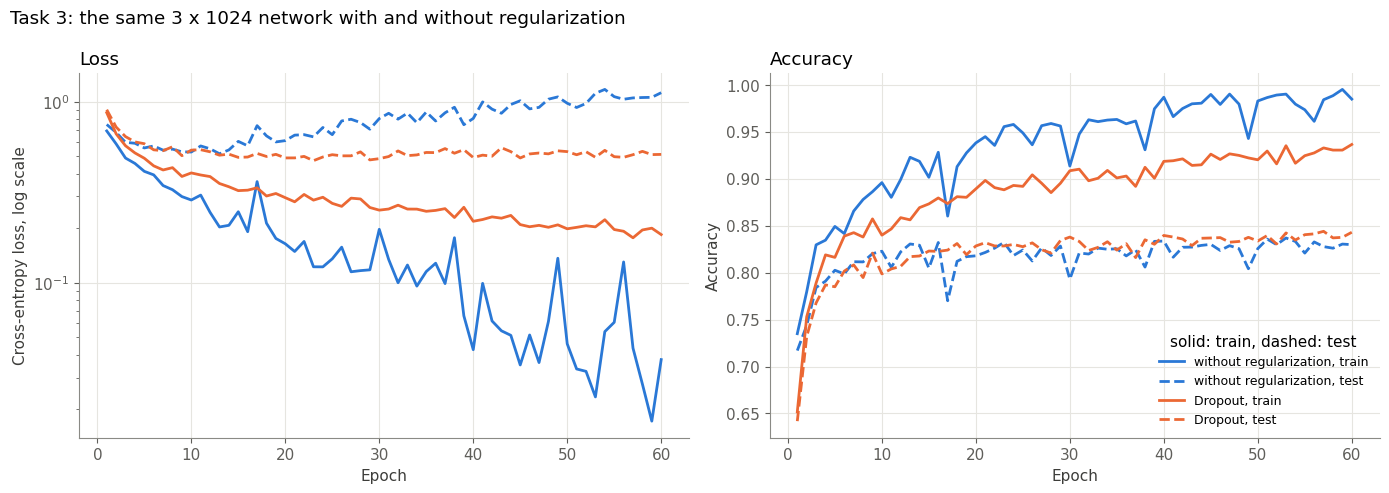

without regularization   | train acc 0.9850 | test acc 0.8299 | train-test gap 0.1551 | test loss: min 0.5152, final 1.1195
with regularization      | train acc 0.9367 | test acc 0.8431 | train-test gap 0.0936 | test loss: min 0.4720, final 0.5111


In [27]:
torch.manual_seed(0)
model = FixedNeuralNetwork().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_func = nn.CrossEntropyLoss()

fixed_history = fit(model, opt, loss_func, X_small, y_small, n_epochs=N_EPOCHS_SMALL, verbose=False)
plot_histories({'without regularization': overfit_history, 'Dropout': fixed_history},
               'Task 3: the same 3 x 1024 network with and without regularization')

for name, h in (('without regularization', overfit_history), ('with regularization', fixed_history)):
    print('%-24s | train acc %.4f | test acc %.4f | train-test gap %.4f | test loss: min %.4f, final %.4f'
          % (name, h['train_acc'][-1], h['test_acc'][-1], h['train_acc'][-1] - h['test_acc'][-1],
             min(h['test_loss']), h['test_loss'][-1]))

regularization                        train acc   test acc   min test loss   final test loss
none                                     0.9850     0.8299          0.5152            1.1195
BatchNorm only                           0.9997     0.8224          0.5313            1.0980
weight decay only                        0.9830     0.8313          0.5145            0.7545
Dropout + weight decay                   0.9157     0.8380          0.4657            0.4948
Dropout + weight decay + BatchNorm       0.9623     0.8314          0.4812            0.5305
Dropout (final)                          0.9367     0.8431          0.4720            0.5111


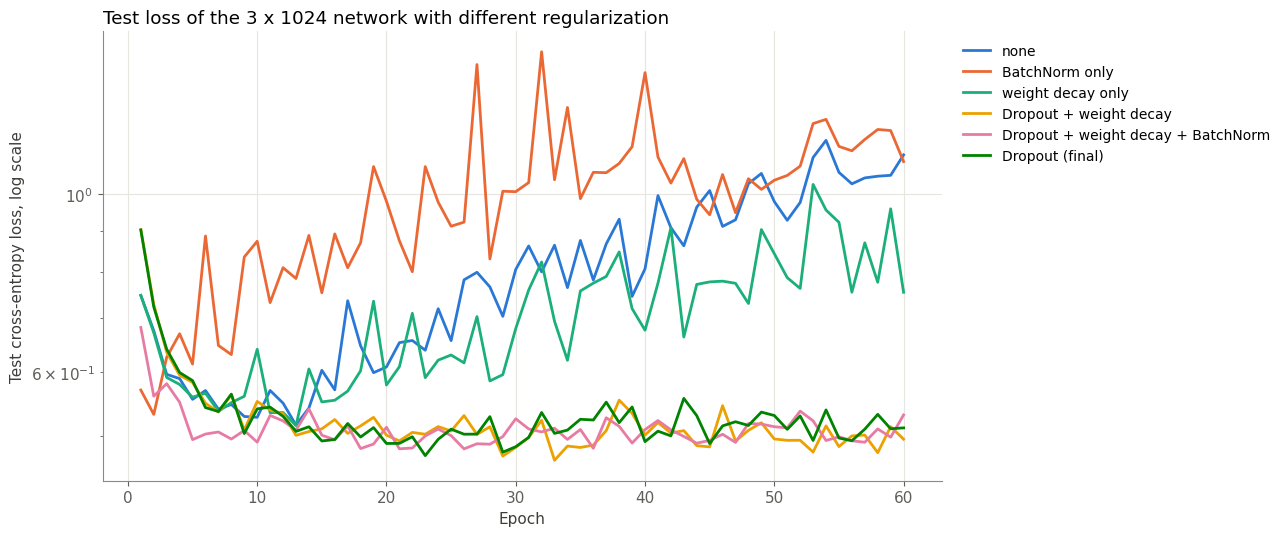

In [28]:
ablation_configs = {
    'BatchNorm only': dict(input_dropout=0.0, dropout=0.0, use_batchnorm=True, weight_decay=0.0),
    'weight decay only': dict(input_dropout=0.0, dropout=0.0, use_batchnorm=False, weight_decay=0.5),
    'Dropout + weight decay': dict(input_dropout=0.2, dropout=0.5, use_batchnorm=False, weight_decay=0.5),
    'Dropout + weight decay + BatchNorm': dict(input_dropout=0.2, dropout=0.5, use_batchnorm=True, weight_decay=0.5),
}
ablation = {'none': overfit_history}
for name, config in ablation_configs.items():
    torch.manual_seed(0)
    net = FixedNeuralNetwork(input_dropout=config['input_dropout'], dropout=config['dropout'],
                             use_batchnorm=config['use_batchnorm']).to(device)
    net_opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=config['weight_decay'])
    ablation[name] = fit(net, net_opt, nn.CrossEntropyLoss(), X_small, y_small, n_epochs=N_EPOCHS_SMALL, verbose=False)
ablation['Dropout (final)'] = fixed_history

print('%-36s %10s %10s %15s %17s' % ('regularization', 'train acc', 'test acc', 'min test loss', 'final test loss'))
for name, h in ablation.items():
    print('%-36s %10.4f %10.4f %15.4f %17.4f' % (name, h['train_acc'][-1], h['test_acc'][-1],
                                                 min(h['test_loss']), h['test_loss'][-1]))

fig, ax = plt.subplots(figsize=(13, 5.5))
for color, (name, h) in zip(SERIES_COLORS + ['#008300'], ablation.items()):
    ax.plot(np.arange(1, N_EPOCHS_SMALL + 1), h['test_loss'], color=color, label=name)
ax.set_yscale('log')
ax.set_xlabel('Epoch')
ax.set_ylabel('Test cross-entropy loss, log scale')
ax.set_title('Test loss of the 3 x 1024 network with different regularization', loc='left')
ax.legend(fontsize=10, loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### Conclusions:
_Write down small report with your conclusions and your ideas._

**Task 1** 
Сеть с двумя скрытыми слоями (512 и 256), `BatchNorm` и `Dropout(0.2)`, Adam (`lr = 1e-3`, уменьшается вдвое каждые 5 эпох), 15 эпох на всех картинках. Точность на тесте **0.8995** - порог пройден.

**Task 2** 
Чтобы переобучение было наглядным, обучающая выборка уменьшена до 3000 картинок, и сети обучаются 60 эпох без регуляризации. Сложность меняется шириной трех скрытых слоев: 16, 64, 256, 1024 нейрона.
- С ростом сложности train loss падает с 0.31 до 0.04, а train accuracy растет с 0.90 до 0.98. Test loss при этом растёт с 0.55 до 0.97, а test accuracy стоит на месте (~0.82). Разрыв между train и test увеличивается с каждым шагом сложности.
- У сети 3 x 1024 test loss минимален на 10-й эпохе (0.517), после чего удваивается к 60-й (0.974). Train accuracy 98.5%, test accuracy 83%.
- Точность на тесте падает слабо, а loss растет сильно. Есть переобучение: сеть запоминает обучающие примеры и становится все увереннее в своих ошибках на новых данных, а cross-entropy за уверенные ошибки штрафует сильно.

**Task 3** 
Та же сеть 3 х 1024 на тех же 3000 картинках, но с `Dropout(0.2)` на входе и `Dropout(0.5)` после каждого скрытого слоя:
- test loss больше не растет и держится около 0.5 (в конце 0.511 против 0.974);
- разрыв train/test accuracy сократился с 0.154 до 0.091;
- test accuracy выросла с 0.8305 до **0.8404**.

Абляция показывает, что работает именно Dropout:
- **BatchNorm сам по себе ухудшает ситуацию** (test accuracy 0.805, test loss 1.24). Он ускоряет подгонку под обучающую выборку, а регуляризующий эффект при батче 128 слабый.
- **Weight decay** в одиночку помогает мало (test loss 0.87 вместо 0.97).
- Добавление weight decay и BatchNorm к Dropout дает тот же test loss (0.508–0.517) и точность 0.829–0.840. Разница меньше 1% и сопоставима с шумом от случайной инициализации, поэтому финальная модель: только Dropout.